# DWBI Week 2 · Task 2 — Inmon, Kimball, and the lifecycle
**Case:** PakFreight · **Evidence files (read-only, never edited):** `marine_shipments.csv`, `rail_shipments.xlsx`, `road_shipments.csv`

## 1. Inmon (top-down) vs Kimball (bottom-up)

| Dimension | Inmon — top-down (CIF) | Kimball — bottom-up (Bus) |
|---|---|---|
| **Starting point** | The whole enterprise: subject areas and one agreed enterprise data model. | One business process (e.g. Shipments) chosen for its business value. |
| **Modelling style** | Normalised (3NF / ER) enterprise warehouse holding atomic data; dimensional marts are derived from it. | Dimensional: star schemas of facts and dimensions, with atomic grain, built per process. |
| **Time to first value** | Slow — the integrated core must exist before marts are useful (months to years). | Fast — the first mart can go live in weeks. |
| **Risk** | Big-bang: high cost, long wait, requirements may drift before anything ships. | Stovepipes: marts built separately drift apart if dimensions are not truly conformed; rework later. |
| **How consistency is enforced** | Centrally: every mart is dependent and loads only from the EDW, so definitions exist once. | By discipline: conformed dimensions and conformed facts shared across marts, planned in the bus matrix. |
| **Relationship of marts to the warehouse** | Marts are subsets *of* the EDW. | The marts *are* the warehouse, joined by the bus. |
| **Best fit** | Many systems, long horizon, enterprise-wide definitions and audit needs. | Fast delivery, one process at a time, teams that can agree dimensions. |

## 2. Both architectures, drawn and labelled (own drawings)

Text(8.5, 0.7, 'Consistency comes from sharing dimensions, not from a central EDW')

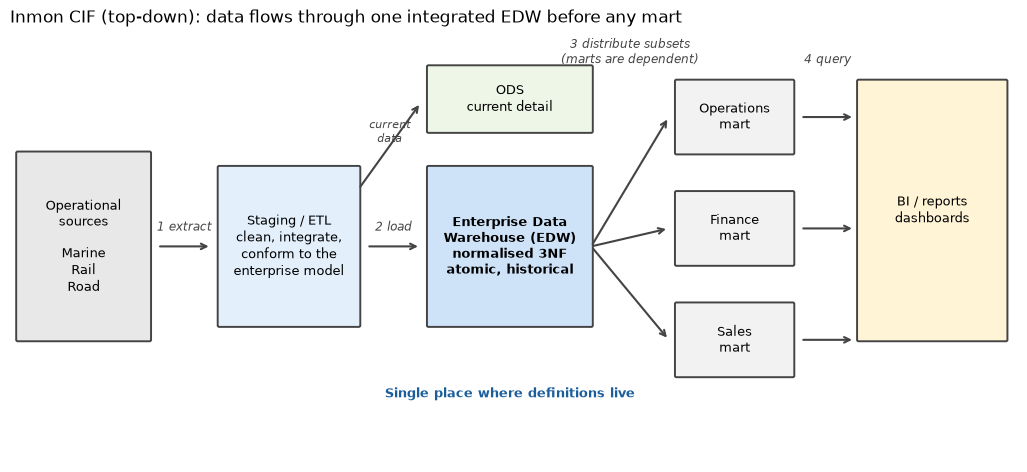

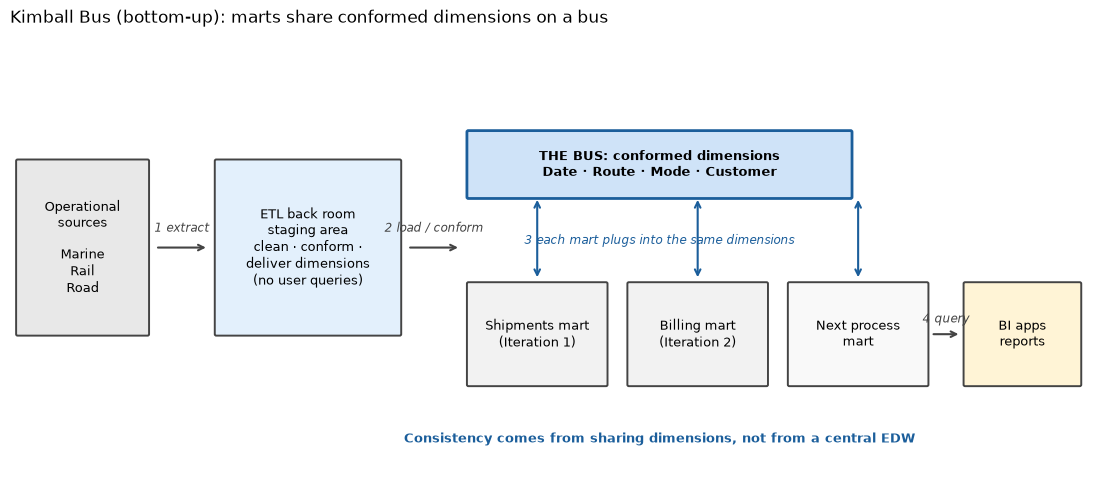

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

def box(ax, x, y, w, h, text, fc="#f2f2f2", ec="#444444", fs=9.5, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02", fc=fc, ec=ec, lw=1.4))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, fontweight="bold" if bold else "normal")

def arrow(ax, x1, y1, x2, y2, label=None, color="#444444", dy=0.18, fs=8.5):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color=color, lw=1.5))
    if label:
        ax.text((x1 + x2) / 2, (y1 + y2) / 2 + dy, label, ha="center", va="bottom", fontsize=fs, color=color, style="italic")

# ---------- Inmon: Corporate Information Factory ----------
fig, ax = plt.subplots(figsize=(13, 5.6))
ax.set_xlim(0, 13); ax.set_ylim(0, 6); ax.axis("off")
ax.set_title("Inmon CIF (top-down): data flows through one integrated EDW before any mart", fontsize=12, loc="left")

box(ax, 0.1, 1.7, 1.7, 2.6, "Operational\nsources\n\nMarine\nRail\nRoad", fc="#e8e8e8")
box(ax, 2.7, 1.9, 1.8, 2.2, "Staging / ETL\nclean, integrate,\nconform to the\nenterprise model", fc="#e3f0fc")
box(ax, 5.4, 1.9, 2.1, 2.2, "Enterprise Data\nWarehouse (EDW)\nnormalised 3NF\natomic, historical", fc="#cfe3f8", bold=True)
box(ax, 5.4, 4.6, 2.1, 0.9, "ODS\ncurrent detail", fc="#eef6e8")
for y, name in [(4.4, "Operations\nmart"), (2.85, "Finance\nmart"), (1.3, "Sales\nmart")]:
    box(ax, 8.6, y - 0.1, 1.5, 1.0, name)
    arrow(ax, 7.5, 3.0, 8.5, y + 0.4)
    arrow(ax, 10.2, y + 0.4, 10.9, y + 0.4)
box(ax, 10.95, 1.7, 1.9, 3.6, "BI / reports\ndashboards", fc="#fff4d6")
arrow(ax, 1.9, 3.0, 2.6, 3.0, "1 extract")
arrow(ax, 4.6, 3.0, 5.3, 3.0, "2 load")
arrow(ax, 4.5, 3.8, 5.3, 5.0, "current\ndata", dy=0.0, fs=8)
ax.text(8.0, 5.55, "3 distribute subsets\n(marts are dependent)", ha="center", fontsize=8.5, style="italic", color="#444444")
ax.text(10.55, 5.55, "4 query", ha="center", fontsize=8.5, style="italic", color="#444444")
ax.text(6.45, 0.9, "Single place where definitions live", ha="center", fontsize=9, color="#1b5e9b", fontweight="bold")

# ---------- Kimball: Bus architecture ----------
fig2, ax2 = plt.subplots(figsize=(14, 6.0))
ax2.set_xlim(0, 14.2); ax2.set_ylim(0, 6.4); ax2.axis("off")
ax2.set_title("Kimball Bus (bottom-up): marts share conformed dimensions on a bus", fontsize=12, loc="left")

box(ax2, 0.1, 2.2, 1.7, 2.4, "Operational\nsources\n\nMarine\nRail\nRoad", fc="#e8e8e8")
box(ax2, 2.7, 2.2, 2.4, 2.4, "ETL back room\nstaging area\nclean · conform ·\ndeliver dimensions\n(no user queries)", fc="#e3f0fc")
arrow(ax2, 1.9, 3.4, 2.6, 3.4, "1 extract")
arrow(ax2, 5.2, 3.4, 5.9, 3.4, "2 load / conform")

ax2.add_patch(FancyBboxPatch((6.0, 4.1), 5.0, 0.9, boxstyle="round,pad=0.02", fc="#cfe3f8", ec="#1b5e9b", lw=2))
ax2.text(8.5, 4.55, "THE BUS: conformed dimensions\nDate · Route · Mode · Customer", ha="center", va="center", fontsize=9.5, fontweight="bold")
for x, name, fc in [(6.0, "Shipments mart\n(Iteration 1)", "#f2f2f2"), (8.1, "Billing mart\n(Iteration 2)", "#f2f2f2"), (10.2, "Next process\nmart", "#f9f9f9")]:
    box(ax2, x, 1.5, 1.8, 1.4, name, fc=fc)
    ax2.annotate("", xy=(x + 0.9, 4.1), xytext=(x + 0.9, 2.95), arrowprops=dict(arrowstyle="<->", color="#1b5e9b", lw=1.5))
ax2.text(8.5, 3.45, "3 each mart plugs into the same dimensions", ha="center", fontsize=8.5, style="italic", color="#1b5e9b")
box(ax2, 12.5, 1.5, 1.5, 1.4, "BI apps\nreports", fc="#fff4d6")
arrow(ax2, 12.05, 2.2, 12.45, 2.2, "4 query", dy=0.12)
ax2.text(8.5, 0.7, "Consistency comes from sharing dimensions, not from a central EDW", ha="center", fontsize=9, color="#1b5e9b", fontweight="bold")

## 3. Ten scenarios

| # | Scenario | Answer | One reason |
|---|---|---|---|
| 1 | Bank needs one enterprise definition of "customer" before any reporting | **Inmon** | The enterprise model and definitions come first, before any mart. |
| 2 | Startup needs a sales dashboard in six weeks | **Kimball** | One process, delivered fast; no time for an enterprise model. |
| 3 | Hospital group, five systems, three-year regulatory programme | **Inmon** | Long horizon, many systems and audit needs justify an integrated, normalised core first. |
| 4 | PakFreight builds the Shipments mart first, with conformed Date and Route | **Kimball** | One process first, joined to later marts through conformed dimensions. |
| 5 | Retailer with a normalised core warehouse feeding departmental marts | **Inmon** | Normalised EDW with dependent marts is the CIF pattern. |
| 6 | Telecom lakehouse with bronze, silver, gold layers | **Hybrid** | Bronze/silver is a central integrated layer (Inmon-like); gold is dimensional marts (Kimball-like). |
| 7 | Census programme where the model must be agreed before loading | **Inmon** | Model first, load second is top-down. |
| 8 | E-commerce team adds a Returns mart reusing the existing Product dimension | **Kimball** | A new process mart plugged into an existing conformed dimension. |
| 9 | Manufacturer built six marts and cannot reconcile them | **Hybrid** | The marts were built bottom-up without conformance; the fix is a top-down shared integration layer or retrofitted conformed dimensions. |
| 10 | Bank integrating a newly acquired competitor's systems | **Inmon** | Two sets of customer and account definitions must be reconciled in one integrated model before reporting. |

*Scenarios 3, 9 and 10 are judgement calls; the reason column states the assumption each rests on.*

## 4. Kimball lifecycle — PakFreight Iteration 1 (Shipments)

Five phases chosen: programme planning, business requirements, dimensional modelling, ETL design and development, BI application.

First, evidence from the files that the phases below rely on.

In [2]:
from pathlib import Path
import pandas as pd

DATA = Path(".") if Path("marine_shipments.csv").exists() else Path("/mnt/user-data/uploads")

# Read-only loads. Source files are never written back.
marine = pd.read_csv(DATA / "marine_shipments.csv", dtype=str, keep_default_na=False)
road   = pd.read_csv(DATA / "road_shipments.csv",   dtype=str, keep_default_na=False)
rail   = pd.read_excel(DATA / "rail_shipments.xlsx", header=2, dtype=object)

print("Columns per file")
for name, df in [("marine", marine), ("rail", rail), ("road", road)]:
    print(f"  {name:6}: {list(df.columns)}")
has_distance = [n for n, df in [("marine", marine), ("rail", rail), ("road", road)]
                if any(("dist" in str(c).lower()) or ("km" in str(c).lower().replace("kg", "")) for c in df.columns)]
print("\nFiles with a distance column:", has_distance or "none")

print("\nDistinct 'Karachi' location names (Route must conform these):")
names = pd.concat([marine["Origin_Port"], marine["Dest_Port"], rail["From Station"], rail["To Station"], road["from_city"], road["to_city"]])
print(sorted({n.strip() for n in names if "karachi" in n.lower() or "pipri" in n.lower()}))
print("\nFiles with a customer column:", [n for n, df in [("marine", marine), ("rail", rail), ("road", road)] if any("cust" in str(c).lower() for c in df.columns)] or "none")

Columns per file
  marine: ['Shipment_ID', 'Ship_Date', 'Origin_Port', 'Dest_Port', 'Weight_KG', 'Cost_PKR', 'Status']
  rail  : ['Consignment No', 'Dispatch Date', 'From Station', 'To Station', 'Weight (Tons)', 'Freight Charges (PKR)', 'Status']
  road  : ['trip_id', 'trip_date', 'from_city', 'to_city', 'weight_kg', 'cost_pkr', 'status']

Files with a distance column: none

Distinct 'Karachi' location names (Route must conform these):
['Karachi', 'Karachi Cantt', 'Karachi Port', 'Pipri Marshalling Yard']

Files with a customer column: none


| Phase | What specifically happens for Shipments (Iteration 1) |
|---|---|
| **Programme planning** | Scope is one process, Shipments, across Marine, Rail and Road. Success test: Operations, Finance and Sales all report the same total tonnage, 578,650 kg across 34 shipments for February 2026. A business owner (not IT) is named to decide what counts as "one shipment". |
| **Business requirements** | Interview Operations, Finance and Sales. Capture the questions: tonnage and cost by mode and month, delayed shipments by route, cost per tonne-km. The files then show what is possible (see the evidence above and section 6). |
| **Dimensional modelling** | Declare the grain first: one row per shipment (one trip, consignment or shipment). Fact `FactShipment` holds `WeightKG` and `CostPKR`. Conformed dimensions: **Date**, **Route** (origin and destination, with names standardised across Karachi Port / Karachi Cantt / Karachi, etc.), **Mode** (Marine / Rail / Road), plus a **Status** attribute (Delivered / In Transit / Delayed). |
| **ETL design and development** | One staging query per file, raw kept as received. Rail: skip two title rows, convert tons to kg. Marine: parse dd/mm/yyyy text as dates. Road: remove the blank row, the `TOTAL` row (a report total, not a shipment) and the duplicate `rd-505` (same row repeated). All files: trim and standardise status, add `MR-` / `RL-` / `RD-` ID prefixes, add a `SourceSystem` column. Log every removed row with its reason. Validate: 34 rows and 578,650 kg, then load one table to the model. |
| **BI application specification and development** | A report on the one Shipments table: tonnage and cost by mode and month, delayed shipments by route, and a drill from total to shipment row. Every number traces to file, row and transformation. |

## 5. Iteration 2: Billing

**Two dimensions Iteration 1 should have built:** **Customer** and **Mode** (Date and Route already exist).
- **Customer:** Billing invoices customers, so it cannot be sliced without it. *None of the three files has a customer column* (see the evidence cell), so it must be sourced from outside them. This is a gap Iteration 1 should have caught.
- **Mode:** Revenue from Billing and cost from Shipments only compare by mode, e.g. for the board's mode profitability, if both use the same Mode dimension.

**What "conformed" means here:** a conformed dimension is one dimension used by both marts, with identical keys, attribute names and business meaning (e.g. `Mode` = Marine, Rail, Road, coded the same way in Shipments and Billing). Because both fact tables point to the same rows, Billing and Shipments figures can be placed side by side and sliced by the same attributes without reconciliation (drill-across).

## 6. SDLC vs CLDS

**The difference:** In the classic SDLC, requirements come first and drive everything: requirements → analysis → design → program → test → deploy. Requirements are assumed knowable up front. Inmon's CLDS reverses it for warehouses: data → warehouse → programs/marts → analysis → understand requirements, and then the loop repeats. The data is gathered and integrated first, and requirements are refined from what people see.

**Why warehouse projects discover requirements only after looking at the data:** users can usually describe the question they have today, but not what the data can answer, how clean it is, or what it lacks. Only when the integrated data is in front of them do the real definitions, gaps and new questions appear.

**Example from these files:** Finance wants *freight cost per tonne-km* (Task 1, requirement b). That sounds like a clear requirement, but the evidence cell shows that none of the three files has a distance column. Only by looking at the data does it emerge that the requirement needs a new data source: distances per route, held in the Route dimension.

## 7. "We built the Shipments mart first, with conformed Date and Route dimensions."

**Bottom-up (Kimball).** It starts from one business process and relies on conformed dimensions to keep later marts consistent, which is the bus approach.

**What would have had to be true for top-down to be right:**
- The mart would have been loaded from a normalised, enterprise-wide EDW rather than directly from staged files, with Shipments as a dependent subset of it.
- That EDW would have had to exist first, modelling all enterprise subjects (shipment, customer, billing, route) with agreed definitions.
- PakFreight would have needed the time and funding for a long programme before the first report, a single owner for enterprise definitions, and enough source systems or audit demands to justify it.